# TAF Optimización: Timetabling de aulas y horarios


# Parte 1: Carga y validación de datos

1. Permite al usuario **subir sus propios archivos CSV** (nada hardcodeado).
2. Valida columnas, tipos, duplicados e integridad entre tablas.
3. Hace chequeos de factibilidad previos al modelo.
4. Deja los datos listos en estructuras (`datos`) para armar el modelo de optimización en la Parte 2.

**Archivos esperados:** `aulas.csv`, `clases.csv`, `franjas.csv`, `profesores.csv`, `disponibilidad_profesores.csv`


## 1. Imports y configuración

In [1]:
import io
import os
import re
import math
import pandas as pd

try:
    from google.colab import files
    EN_COLAB = True
except ImportError:
    EN_COLAB = False

# Solo se usa fuera de Colab (pruebas locales): carpeta donde están los CSV
RUTA_LOCAL = "."

# Parámetros que usan las dos partes
SLOT_DURATION = 30   # resolución de la grilla horaria (min): horas y duraciones tienen que ser múltiplo
K_AULAS = 10         # aulas candidatas por clase: las K compatibles más chicas (None = todas)

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)


def time_to_mins(t_str):
    """'HH:MM' -> minutos desde las 00:00. Lanza ValueError si el formato no es válido."""
    t_str = str(t_str)
    if not re.fullmatch(r"\d{2}:\d{2}", t_str):
        raise ValueError(f"hora inválida: {t_str!r}")
    h, m = map(int, t_str.split(":"))
    if h > 23 or m > 59:
        raise ValueError(f"hora inválida: {t_str!r}")
    return h * 60 + m


## 2. Esquema esperado de cada archivo

Define qué columnas necesita cada tabla. Si más adelante agregan columnas (por ejemplo `accesible` en aulas), se suman acá.

In [2]:
ESQUEMA = {
    "aulas.csv": ["aula_id", "nombre", "edificio", "capacidad", "tiene_proyector", "es_laboratorio"],
    "clases.csv": ['clase_id', 'materia', 'cohorte', 'carrera', 'anio', 'tipo', 'cantidad_alumnos', 'franja', 'duracion_min', 'profesor_id', 'requiere_proyector', 'requiere_laboratorio'],
    "franjas.csv": ['dia', 'franja', 'hora_inicio', 'hora_fin'],
    "profesores.csv": ['profesor_id', 'nombre', 'dedicacion', 'max_min_por_dia'],
    "disponibilidad_profesores.csv": ['profesor_id', 'dia', 'hora_desde', 'hora_hasta'],
}
BINARIAS = {
    "aulas.csv": ["tiene_proyector", "es_laboratorio"],
    "clases.csv": ["requiere_proyector", "requiere_laboratorio"],
}
CLAVES = {
    "aulas.csv": "aula_id", "clases.csv": "clase_id", "profesores.csv": "profesor_id",
}
# Pares de columnas horarias (inicio, fin) en formato HH:MM
HORAS = {
    "franjas.csv": [("hora_inicio", "hora_fin")],
    "disponibilidad_profesores.csv": [("hora_desde", "hora_hasta")],
}

## 3. Subir los archivos

En Colab se abre un selector: elegí los 5 CSV a la vez. (Fuera de Colab se leen desde `RUTA_LOCAL`.)

In [3]:
def cargar_archivos():
    """Devuelve un dict {nombre_archivo: DataFrame}."""
    contenidos = {}
    if EN_COLAB:
        subidos = files.upload()
        for nombre, data in subidos.items():
            # Colab renombra duplicados como "archivo (1).csv": lo normalizamos
            limpio = re.sub(r" \(\d+\)(\.csv)$", r"\1", nombre)
            contenidos[limpio] = data
        dfs = {n: pd.read_csv(io.BytesIO(d), encoding="utf-8") for n, d in contenidos.items()}
    else:
        import os
        dfs = {n: pd.read_csv(os.path.join(RUTA_LOCAL, n), encoding="utf-8")
               for n in ESQUEMA if os.path.exists(os.path.join(RUTA_LOCAL, n))}
    return dfs

dfs = cargar_archivos()
print("Archivos cargados:", list(dfs))
faltan = [n for n in ESQUEMA if n not in dfs]
if faltan:
    print("FALTAN:", faltan)

Saving aulas.csv to aulas.csv
Saving clases.csv to clases.csv
Saving disponibilidad_profesores.csv to disponibilidad_profesores.csv
Saving franjas.csv to franjas.csv
Saving profesores.csv to profesores.csv
Archivos cargados: ['aulas.csv', 'clases.csv', 'disponibilidad_profesores.csv', 'franjas.csv', 'profesores.csv']


## 4. Validación de los datos

Cada chequeo registra un **error** (hay que corregir el archivo) o una **advertencia** (se puede seguir, pero conviene revisar).

In [4]:
errores, advertencias = [], []

def err(msg): errores.append(msg)
def warn(msg): advertencias.append(msg)


# Helpers que también usa preparar_datos (sección 6)
def ventanas_de(fr):
    """(día, franja) -> (minuto de inicio, minuto de fin)."""
    return {(r.dia, r.franja): (time_to_mins(r.hora_inicio), time_to_mins(r.hora_fin)) for r in fr.itertuples()}

def minutos_disponibles_de(dp):
    """(docente, día) -> conjunto de minutos disponibles (múltiplos de SLOT_DURATION).
    Da igual si un intervalo viene partido en dos filas pegadas (ej. 14-16 y 16-18)."""
    libres = {}
    for r in dp.itertuples():
        libres.setdefault((r.profesor_id, r.dia), set()).update(
            range(time_to_mins(r.hora_desde), time_to_mins(r.hora_hasta), SLOT_DURATION))
    return libres


def validar_estructura(dfs):
    for nombre, cols in ESQUEMA.items():
        if nombre not in dfs:
            err(f"{nombre}: archivo no cargado"); continue
        df = dfs[nombre]
        faltan = [c for c in cols if c not in df.columns]
        if faltan:
            err(f"{nombre}: faltan columnas {faltan}")
        if df.empty:
            err(f"{nombre}: está vacío")
        nulos = df[[c for c in cols if c in df.columns]].isna().sum()
        for col, n in nulos.items():
            if n:
                err(f"{nombre}: columna '{col}' tiene {n} valores vacíos")
        if nombre in CLAVES and CLAVES[nombre] in df.columns:
            dup = df[CLAVES[nombre]].duplicated().sum()
            if dup:
                err(f"{nombre}: {dup} IDs duplicados en '{CLAVES[nombre]}'")
        for col in BINARIAS.get(nombre, []):
            if col in df.columns and not df[col].isin([0, 1]).all():
                err(f"{nombre}: '{col}' debe ser 0/1")

def validar_valores(dfs):
    if (dfs["aulas.csv"].capacidad <= 0).any():
        err("aulas.csv: hay capacidades <= 0")
    c = dfs["clases.csv"]
    if (c.cantidad_alumnos <= 0).any():
        err("clases.csv: hay clases con cantidad_alumnos <= 0")
    if (c.duracion_min <= 0).any():
        err("clases.csv: duracion_min debe ser > 0")
    malas = c.clase_id[c.duracion_min % SLOT_DURATION != 0].tolist()
    if malas:
        err(f"clases.csv: duraciones que no son múltiplo de {SLOT_DURATION} min: {malas[:10]}")
    if (dfs["profesores.csv"].max_min_por_dia <= 0).any():
        err("profesores.csv: max_min_por_dia debe ser > 0")
    # Horas: formato HH:MM, múltiplo de la grilla e inicio < fin
    for nombre, pares in HORAS.items():
        for col_ini, col_fin in pares:
            for i, r in dfs[nombre].iterrows():
                try:
                    a, b = time_to_mins(r[col_ini]), time_to_mins(r[col_fin])
                except ValueError as e:
                    err(f"{nombre} fila {i}: {e}"); continue
                if a % SLOT_DURATION or b % SLOT_DURATION:
                    err(f"{nombre} fila {i}: horas que no son múltiplo de {SLOT_DURATION} min")
                if a >= b:
                    err(f"{nombre} fila {i}: '{col_ini}' tiene que ser menor que '{col_fin}'")

def validar_integridad(dfs):
    cl, pr = dfs["clases.csv"], dfs["profesores.csv"]
    dp, fr = dfs["disponibilidad_profesores.csv"], dfs["franjas.csv"]
    sin_prof = set(cl.profesor_id) - set(pr.profesor_id)
    if sin_prof:
        err(f"clases.csv: docentes que no existen en profesores.csv: {sorted(sin_prof)}")
    franjas_malas = set(cl.franja) - set(fr.franja)
    if franjas_malas:
        err(f"clases.csv: franjas que no existen en franjas.csv: {sorted(franjas_malas)}")
    dup = fr.duplicated(["dia", "franja"]).sum()
    if dup:
        err(f"franjas.csv: {dup} filas repetidas para el mismo día y franja")
    dias_malos = set(dp.dia) - set(fr.dia)
    if dias_malos:
        err(f"disponibilidad_profesores.csv: días que no están en franjas.csv: {sorted(dias_malos)}")
    desconocidos = set(dp.profesor_id) - set(pr.profesor_id)
    if desconocidos:
        err(f"disponibilidad_profesores.csv: docentes que no existen en profesores.csv: {sorted(desconocidos)}")
    sin_disp = set(pr.profesor_id) - set(dp.profesor_id)
    if sin_disp:
        warn(f"Docentes sin filas de disponibilidad: {sorted(sin_disp)}")
    sin_clases = set(pr.profesor_id) - set(cl.profesor_id)
    if sin_clases:
        warn(f"{len(sin_clases)} docentes no tienen clases asignadas")

def chequeos_factibilidad(dfs):
    """Condiciones necesarias, antes de armar el modelo: cada clase tiene al menos un aula
    posible (D2, D3) y al menos un horario de inicio posible (D1, D5, D7)."""
    au, cl, fr = dfs["aulas.csv"], dfs["clases.csv"], dfs["franjas.csv"]
    max_dia = dfs["profesores.csv"].set_index("profesor_id").max_min_por_dia

    # (a) Aula compatible
    for c in cl.itertuples():
        ok = au[au.capacidad >= c.cantidad_alumnos]
        if c.requiere_laboratorio:
            ok = ok[ok.es_laboratorio == 1]
        if c.requiere_proyector:
            ok = ok[ok.tiene_proyector == 1]
        if ok.empty:
            err(f"Clase {c.clase_id} ({c.materia}, {c.cantidad_alumnos} alumnos): no hay ningún aula compatible")

    # (b) Horario posible: entra en su franja algún día y el docente está disponible toda la clase
    ventanas = ventanas_de(fr)
    libres = minutos_disponibles_de(dfs["disponibilidad_profesores.csv"])
    for c in cl.itertuples():
        if c.duracion_min > max_dia[c.profesor_id]:
            err(f"Clase {c.clase_id}: dura {c.duracion_min} min, más que el max_min_por_dia de {c.profesor_id}")
            continue
        posibles = [(d, a, b) for (d, f), (a, b) in ventanas.items() if f == c.franja and b - a >= c.duracion_min]
        if not posibles:
            err(f"Clase {c.clase_id}: dura {c.duracion_min} min y no entra en la franja {c.franja}")
            continue
        hay_inicio = any(
            all(t in libres.get((c.profesor_id, d), ()) for t in range(t0, t0 + c.duracion_min, SLOT_DURATION))
            for d, a, b in posibles for t0 in range(a, b - c.duracion_min + 1, SLOT_DURATION))
        if not hay_inicio:
            err(f"Clase {c.clase_id} ({c.materia}): {c.profesor_id} no tiene ningún hueco de "
                f"{c.duracion_min} min en la franja {c.franja}")
    print("Chequeos de factibilidad completados (aulas y horarios).")

# Cada etapa corre solo si la anterior no encontró errores
validar_estructura(dfs)
if not errores:
    validar_valores(dfs)
if not errores:
    validar_integridad(dfs)
if not errores:
    chequeos_factibilidad(dfs)

print(f"\n{len(errores)} errores, {len(advertencias)} advertencias")
for e in errores: print("  ERROR:", e)
for a in advertencias: print("  AVISO:", a)
if not errores:
    print("Datos válidos, se puede continuar.")

Chequeos de factibilidad completados (aulas y horarios).

0 errores, 0 advertencias
Datos válidos, se puede continuar.


## 5. Vista previa de las tablas

In [5]:
for nombre, df in dfs.items():
    print(f"\n=== {nombre}  ({df.shape[0]} filas x {df.shape[1]} columnas) ===")
    display(df.head(5)) if "display" in globals() else print(df.head(5))


=== aulas.csv  (200 filas x 6 columnas) ===
  aula_id       nombre edificio  capacidad  tiene_proyector  es_laboratorio
0    A001  Aula AN-101    Anexo        120                1               0
1    A002  Aula AN-102    Anexo        110                1               0
2    A003  Aula AN-103    Anexo        100                1               0
3    A004  Aula AN-104    Anexo        100                1               0
4    A005  Aula AN-105    Anexo        100                1               0

=== clases.csv  (1003 filas x 12 columnas) ===
  clase_id                       materia cohorte          carrera  anio      tipo  cantidad_alumnos  franja  duracion_min profesor_id  requiere_proyector  \
0     C001                      Física I  IND-1A  Ing. Industrial     1   teórica                89  mañana           120        D231                   1   
1     C002                      Física I  IND-1A  Ing. Industrial     1  práctica                89   tarde           120        D231    

## 6. Estructuras listas para el modelo

Convierte las tablas en diccionarios y conjuntos para usar directo en la Parte 2 (modelo en OR-Tools / PuLP / Pyomo).

In [6]:
def preparar_datos(dfs):
    au, cl = dfs["aulas.csv"], dfs["clases.csv"]
    fr, pr = dfs["franjas.csv"], dfs["profesores.csv"]
    dp = dfs["disponibilidad_profesores.csv"]

    # Aulas compatibles por clase (D2 capacidad, D3 proyector/laboratorio).
    # Las clases que no requieren laboratorio pueden usar uno: se penaliza en B5.
    # Se ordenan de menor a mayor capacidad y quedan las K_AULAS más chicas
    # (B1 ya favorece las chicas, así que casi no se pierde nada y el modelo se achica mucho).
    compat = {}
    for c in cl.itertuples():
        ok = au[au.capacidad >= c.cantidad_alumnos]
        if c.requiere_laboratorio:
            ok = ok[ok.es_laboratorio == 1]
        if c.requiere_proyector:
            ok = ok[ok.tiene_proyector == 1]
        compat[c.clase_id] = list(ok.sort_values("capacidad").aula_id[:K_AULAS])

    return {
        "aulas": au.set_index("aula_id").to_dict("index"),
        "clases": cl.set_index("clase_id").to_dict("index"),
        "docentes": pr.set_index("profesor_id").to_dict("index"),
        "franjas": fr.to_dict("records"),
        "dias": list(dict.fromkeys(fr.dia)),               # orden del archivo (LUN, MAR, ...), no alfabético
        "ventanas": ventanas_de(fr),                       # (día, franja) -> (min inicio, min fin)
        "minutos_disponibles": minutos_disponibles_de(dp), # (docente, día) -> set de minutos
        "aulas_compatibles": compat,
        "cohortes": {k: list(v.clase_id) for k, v in cl.groupby("cohorte")},
        "clases_por_docente": {k: list(v.clase_id) for k, v in cl.groupby("profesor_id")},
    }

if not errores:
    datos = preparar_datos(dfs)
    print({k: len(v) for k, v in datos.items()})
    ejemplo = next(iter(datos["clases"]))
    print(f"\nEjemplo: la clase {ejemplo} puede ir en {datos['aulas_compatibles'][ejemplo]}")

{'aulas': 200, 'clases': 1003, 'docentes': 287, 'franjas': 15, 'dias': 5, 'ventanas': 15, 'minutos_disponibles': 1081, 'aulas_compatibles': 1003, 'cohortes': 134, 'clases_por_docente': 287}

Ejemplo: la clase C001 puede ir en ['A034', 'A004', 'A005', 'A003', 'A033', 'A002', 'A001', 'A032', 'A136', 'A135']


In [7]:
for e in errores: print(e)

# Parte 2:

Con `datos` ya cargado se arma el modelo (OR-Tools CP-SAT):
- Variables binarias `y[clase, día, slot_inicio]` (horario) y `x[clase, aula, día, slot_inicio]` (horario + aula), con `Σ_aulas x = y`.
- Restricciones duras **D1–D7** (asignación única dentro de la franja, capacidad, proyector/laboratorio, aulas, docentes, cohortes, tope diario).
- Función objetivo con penalizaciones por restricciones blandas **B1–B5**.
- Resolución, verificación de la solución contra las restricciones duras y descarga del resultado.
- (Pendiente) Visualización de la grilla semanal.

La numeración D1–D7 y B1–B5 es la de `restricciones.md`.

## 1. Configuración inicial y discretización horaria

In [8]:
!pip install ortools
from ortools.sat.python import cp_model

# Instanciar el modelo
model = cp_model.CpModel()

# El tiempo se discretiza en slots de SLOT_DURATION minutos (definido en la Parte 1).
# La grilla sale de franjas.csv: no hay horarios fijos en el código.
dias_unicos = datos["dias"]        # LUN, MAR, MIÉ, JUE, VIE (orden del archivo)
ventana = datos["ventanas"]        # (día, franja) -> (minuto de inicio, minuto de fin)

# La grilla va desde la primera apertura hasta el último cierre de cualquier franja
MIN_INICIO = min(a for a, _ in ventana.values())
MIN_FIN = max(b for _, b in ventana.values())
num_slots_por_dia = (MIN_FIN - MIN_INICIO) // SLOT_DURATION

def slot_de(minuto):
    """Minuto del día -> índice de slot (0 = MIN_INICIO)."""
    return (minuto - MIN_INICIO) // SLOT_DURATION

def minuto_de(slot):
    """Índice de slot -> minuto del día."""
    return MIN_INICIO + slot * SLOT_DURATION

# Slots que pertenecen a alguna franja, por día y en orden. Los cortes entre franjas
# (ej. el almuerzo de 13 a 14) quedan afuera: nunca se usan ni cuentan como hueco en B2.
slots_validos = {
    d: sorted({slot_de(t) for (dd, _), (a, b) in ventana.items() if dd == d
               for t in range(a, b, SLOT_DURATION)})
    for d in dias_unicos
}

print(f"Grilla de {SLOT_DURATION} min entre {MIN_INICIO // 60:02d}:{MIN_INICIO % 60:02d} y "
      f"{MIN_FIN // 60:02d}:{MIN_FIN % 60:02d}: {num_slots_por_dia} slots por día, "
      f"{len(slots_validos[dias_unicos[0]])} dentro de franjas (el resto son cortes entre franjas).")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 29.8/29.8 MB 73.4 MB/s  0:00:00
Grilla de 30 min entre 08:00 y 22:00: 28 slots por día, 26 dentro de franjas (el resto son cortes entre franjas).


## 2. Definición de las variables de decisión

In [9]:
# 2. Variables de decisión
#
# y[(clase, dia, slot)]       = 1 si la clase empieza ese día en ese slot          (horario)
# x[(clase, aula, dia, slot)] = 1 si además se dicta en esa aula                   (horario + aula)
# Vínculo: para cada (clase, día, slot), Σ_aulas x = y. Si la clase arranca ahí, va en exactamente un aula.
#
# Solo se crean variables para combinaciones que ya cumplen:
#   D1 (parte franja): el inicio está en la franja de la clase y la clase termina antes de que cierre.
#   D2, D3: el aula está en aulas_compatibles (capacidad, proyector, laboratorio).
#   D5 (parte disponibilidad): el docente está disponible en todos los slots que ocupa la clase.

x, y = {}, {}

# Índices auxiliares para construir las restricciones
y_por_clase = {}             # clase -> [y]                       (D1)
ocupacion_aula = {}          # (aula, día, slot) -> [x]           (D4)
ocupacion_profesor = {}      # (docente, día, slot) -> [y]        (D5, B3)
ocupacion_cohorte = {}       # (cohorte, día, slot) -> [y]        (D6, B2)
ocupacion_profesor_dia = {}  # (docente, día) -> [(minutos, y)]   (D7, B4)

# Duración de cada clase expresada en slots
duraciones = {}

for c_id, clase in datos["clases"].items():
    duracion_min = int(clase["duracion_min"])
    if duracion_min % SLOT_DURATION != 0:
        raise ValueError(f"La duración de la clase {c_id} no es múltiplo de {SLOT_DURATION} minutos.")
    duracion_slots = duracion_min // SLOT_DURATION
    duraciones[c_id] = duracion_slots

    prof_id = clase["profesor_id"]
    cohorte = clase["cohorte"]
    aulas_posibles = datos["aulas_compatibles"][c_id]

    for dia in dias_unicos:
        if (dia, clase["franja"]) not in ventana:
            continue
        libres = datos["minutos_disponibles"].get((prof_id, dia), set())
        ini_franja, fin_franja = ventana[dia, clase["franja"]]

        # D1: el inicio recorre solo la franja de la clase, y la clase termina antes del cierre
        for inicio in range(ini_franja, fin_franja - duracion_min + 1, SLOT_DURATION):

            # D5: el docente tiene que estar disponible durante toda la clase
            if not all(t in libres for t in range(inicio, inicio + duracion_min, SLOT_DURATION)):
                continue

            slot = slot_de(inicio)
            ocupa = range(slot, slot + duracion_slots)

            # Variables sin nombre: con cientos de miles de variables ahorra mucha memoria
            yv = model.NewBoolVar("")
            y[c_id, dia, slot] = yv
            y_por_clase.setdefault(c_id, []).append(yv)

            xs = []
            for aula_id in aulas_posibles:          # D2, D3: solo aulas compatibles
                v = model.NewBoolVar("")
                x[c_id, aula_id, dia, slot] = v
                xs.append(v)
                for b in ocupa:
                    ocupacion_aula.setdefault((aula_id, dia, b), []).append(v)
            model.Add(sum(xs) == yv)                # vínculo horario <-> aula

            for b in ocupa:
                ocupacion_profesor.setdefault((prof_id, dia, b), []).append(yv)
                ocupacion_cohorte.setdefault((cohorte, dia, b), []).append(yv)
            ocupacion_profesor_dia.setdefault((prof_id, dia), []).append((duracion_min, yv))

# Red de seguridad (la Parte 1 ya lo chequea): toda clase tiene al menos una asignación posible
sin_opciones = [c_id for c_id in datos["clases"] if not y_por_clase.get(c_id)]
if sin_opciones:
    raise ValueError(
        f"Las siguientes clases no tienen asignaciones posibles: {sin_opciones}. "
        "Revisar disponibilidad docente, aulas y franjas.")

print(f"Variables de decisión creadas: {len(y)} y (horario) + {len(x)} x (horario + aula)")
print("Todas las clases tienen al menos una asignación posible.")

Variables de decisión creadas: 14641 y (horario) + 146410 x (horario + aula)
Todas las clases tienen al menos una asignación posible.


## 3. Definición de las restricciones

- **Primera celda: restricciones duras (D1–D7).** Se cumplen siempre; si no se pueden cumplir, el modelo es infactible.
- **Segunda celda: restricciones blandas (B1–B5).** Se pueden violar, pero cada violación suma una penalización a la función objetivo, que se minimiza.

In [10]:
# =============================================================================
#  RESTRICCIONES DURAS (D1–D7)
#  Se cumplen siempre. Algunas ya quedaron garantizadas al crear las variables
#  (sección 2): acá se agregan las demás y se verifica lo que vino por construcción.
# =============================================================================

# -----------------------------------------------------------------------------
# D1: Cada clase se asigna exactamente una vez a un aula y a una hora de inicio,
#     y la clase entera entra en su franja ese día.
#     - Dentro de su franja: por construcción (solo hay y/x para inicios de su franja).
#     - Exactamente una vez: ExactlyOne sobre sus y. El vínculo Σ_aulas x = y le asigna un aula.
# -----------------------------------------------------------------------------
for c_id in datos["clases"]:
    model.AddExactlyOne(y_por_clase[c_id])

# -----------------------------------------------------------------------------
# D2: La capacidad del aula alcanza para los alumnos.
# D3: Si la clase requiere proyector, el aula lo tiene. Si requiere laboratorio,
#     el aula es laboratorio.
#     Las dos por construcción: x solo existe para aulas de aulas_compatibles.
#     Igual se verifican acá.
# -----------------------------------------------------------------------------
for (c_id, aula_id, dia, slot) in x:
    clase, aula = datos["clases"][c_id], datos["aulas"][aula_id]
    assert aula["capacidad"] >= clase["cantidad_alumnos"], ("D2", c_id, aula_id)
    assert aula["tiene_proyector"] >= clase["requiere_proyector"], ("D3", c_id, aula_id)
    assert aula["es_laboratorio"] >= clase["requiere_laboratorio"], ("D3", c_id, aula_id)

# -----------------------------------------------------------------------------
# D4: Un aula no puede tener dos clases a la vez.
#     Para cada (aula, día, slot), como mucho una x que lo ocupe.
# -----------------------------------------------------------------------------
for variables in ocupacion_aula.values():
    if len(variables) > 1:
        model.AddAtMostOne(variables)

# -----------------------------------------------------------------------------
# D5: Un docente no puede dictar dos clases a la vez, y tiene que estar disponible
#     en todos los slots que ocupa cada clase.
#     - No superposición: para cada (docente, día, slot), como mucho una y que lo ocupe.
#     - Disponibilidad: por construcción (no hay y para inicios donde no está disponible).
# -----------------------------------------------------------------------------
for variables in ocupacion_profesor.values():
    if len(variables) > 1:
        model.AddAtMostOne(variables)

# -----------------------------------------------------------------------------
# D6: Una cohorte no puede tener dos clases a la vez.
#     Para cada (cohorte, día, slot), como mucho una y que lo ocupe.
#     Nota: los grupos de laboratorio de una misma comisión comparten cohorte, así que
#     tampoco pueden ir en paralelo. Es más estricto de lo necesario, pero nunca da un
#     horario inválido.
# -----------------------------------------------------------------------------
for variables in ocupacion_cohorte.values():
    if len(variables) > 1:
        model.AddAtMostOne(variables)

# -----------------------------------------------------------------------------
# D7: Un docente no supera max_min_por_dia.
#     Σ (duración · y) del día <= max_min_por_dia · dia_activo
#     dia_activo[docente, día] vale 1 si da alguna clase ese día. Para D7 solo
#     "habilita" el día; la blanda B4 lo usa para contar los días trabajados.
# -----------------------------------------------------------------------------
dia_activo = {}
for (prof_id, dia), asignaciones in ocupacion_profesor_dia.items():
    max_minutos = int(datos["docentes"][prof_id]["max_min_por_dia"])
    dia_activo[prof_id, dia] = model.NewBoolVar("")
    model.Add(sum(duracion * var for duracion, var in asignaciones)
              <= max_minutos * dia_activo[prof_id, dia])

print("Restricciones duras D1–D7 incorporadas correctamente.")

Restricciones duras D1–D7 incorporadas correctamente.


In [11]:
# =============================================================================
#  RESTRICCIONES BLANDAS (B1–B5) Y FUNCIÓN OBJETIVO
#  Cada blanda es una expresión que mide cuánto se viola. El objetivo minimiza
#  la suma ponderada. Las unidades son distintas, así que los pesos hay que calibrarlos.
# =============================================================================

# Pesos de las penalizaciones, en PORCENTAJE (tienen que sumar 100).
# Las blandas tienen unidades distintas (asientos, slots, días), así que cada una se
# normaliza antes de pesarla: B_i / (peor caso de B_i) queda entre 0 y 1.
#     objetivo = Σ pct_i × B_i / máx_i        (0 = ideal, 100 = peor caso en todas a la vez)
PCT_ESPACIO = 17.5           # B1: asientos vacíos
PCT_HUECOS = 22.5            # B2: huecos de cohorte
PCT_RACHA = 22.5             # B3: racha docente por encima de U
PCT_DIAS = 12                # B4: días extra de docentes
PCT_LABORATORIO = 17.5       # B5: laboratorio sin necesitarlo
PCT_DIAS_UNA_MATERIA = 8     # B6: días con una sola materia (docentes con 2+ materias)
assert abs(PCT_ESPACIO + PCT_HUECOS + PCT_RACHA + PCT_DIAS + PCT_LABORATORIO
           + PCT_DIAS_UNA_MATERIA - 100) < 1e-9, "Los porcentajes tienen que sumar 100"

ESCALA = 10**6   # CP-SAT solo acepta coeficientes enteros: los pesos se multiplican por esto

UMBRAL_RACHA_MIN = 360  # U de B3 (equivale a los 3 bloques de 2 h)

cap_lab_max = max((a["capacidad"] for a in datos["aulas"].values() if a["es_laboratorio"]), default=0)

# -----------------------------------------------------------------------------
# B1: Minimizar los asientos vacíos: (capacidad − alumnos) × duración (en slots).
#     Así no se usan aulas grandes para pocos alumnos y quedan libres para las masivas.
# -----------------------------------------------------------------------------
claves_x = list(x)
B1 = cp_model.LinearExpr.WeightedSum(
    [x[k] for k in claves_x],
    [(int(datos["aulas"][a]["capacidad"]) - int(datos["clases"][c]["cantidad_alumnos"])) * duraciones[c]
     for (c, a, _, _) in claves_x])

# -----------------------------------------------------------------------------
# B2: Minimizar el tiempo muerto de cada cohorte en cada día: slots sin clase entre
#     la primera y la última clase del día. Solo se recorren slots_validos, así que
#     el almuerzo no cuenta.
#       antes[i]   = 1 si la cohorte ya tuvo clase en algún slot <= i
#       despues[i] = 1 si todavía tiene clase en algún slot >= i
#       hueco[i]  >= antes[i] + despues[i] − 1 − ocupado[i]
# -----------------------------------------------------------------------------
huecos = []
aux_b2 = []      # (cohorte, día, slots, antes, despues, huecos) para armar pistas en la sección 4
for cohorte in datos["cohortes"]:
    for dia in dias_unicos:
        S = slots_validos[dia]
        if not any(ocupacion_cohorte.get((cohorte, dia, s)) for s in S):
            continue                                    # la cohorte no puede tener clase ese día
        ocupado = [sum(ocupacion_cohorte.get((cohorte, dia, s), [])) for s in S]   # 0/1 por D6
        antes = [model.NewBoolVar("") for _ in S]
        despues = [model.NewBoolVar("") for _ in S]
        huecos_dia = []
        for i in range(len(S)):
            model.Add(antes[i] >= ocupado[i])
            model.Add(despues[i] >= ocupado[i])
            if i > 0:
                model.Add(antes[i] >= antes[i - 1])
            if i < len(S) - 1:
                model.Add(despues[i] >= despues[i + 1])
            hueco = model.NewBoolVar("")
            model.Add(hueco >= antes[i] + despues[i] - 1 - ocupado[i])
            huecos_dia.append(hueco)
        huecos += huecos_dia
        aux_b2.append((cohorte, dia, S, antes, despues, huecos_dia))
B2 = sum(huecos)

# -----------------------------------------------------------------------------
# B3: Penalizar a los docentes por cada slot de clase seguida por encima de U.
#     Se miran ventanas de W = U/slot + 1 slots consecutivos (sin cruzar cortes entre
#     franjas). Si una ventana está toda ocupada, hay un slot por encima de U.
#     Una racha de L slots llena exactamente L − U/slot ventanas = los slots de exceso.
# -----------------------------------------------------------------------------
W = UMBRAL_RACHA_MIN // SLOT_DURATION + 1
rachas = []
aux_b3 = []      # (docente, día, slots de la ventana, racha) para armar pistas en la sección 4
for prof_id in datos["clases_por_docente"]:
    for dia in dias_unicos:
        S = slots_validos[dia]
        for i in range(len(S) - W + 1):
            ventana_slots = S[i:i + W]
            if ventana_slots[-1] - ventana_slots[0] != W - 1:      # cruza un corte (almuerzo)
                continue
            terminos = [v for s in ventana_slots for v in ocupacion_profesor.get((prof_id, dia, s), [])]
            if len(terminos) < W:                                  # imposible llenarla
                continue
            racha = model.NewBoolVar("")
            model.Add(racha >= sum(terminos) - (W - 1))            # ocupados en la ventana − (W − 1)
            rachas.append(racha)
            aux_b3.append((prof_id, dia, ventana_slots, racha))
B3 = sum(rachas)

# -----------------------------------------------------------------------------
# B4: Penalizar a los docentes por los días en que dictan por encima del mínimo
#     necesario: ⌈minutos totales del docente / max_min_por_dia⌉.
#     dia_activo viene de D7. Como D7 limita los minutos por día, la suma de días
#     activos nunca baja del mínimo: la diferencia ya es >= 0 (no hace falta max(0, ·)).
# -----------------------------------------------------------------------------
minimo_dias = {}
for prof_id, clases_prof in datos["clases_por_docente"].items():
    total = sum(int(datos["clases"][c]["duracion_min"]) for c in clases_prof)
    minimo_dias[prof_id] = math.ceil(total / int(datos["docentes"][prof_id]["max_min_por_dia"]))
B4 = sum(dia_activo.values()) - sum(minimo_dias.values())

# -----------------------------------------------------------------------------
# B5: Penalizar los slots de laboratorio usados por clases que no lo necesitan
#     (por duración, igual que B1).
# -----------------------------------------------------------------------------
lab_sin_necesidad = [(var, duraciones[c]) for (c, a, _, _), var in x.items()
                     if not datos["clases"][c]["requiere_laboratorio"] and datos["aulas"][a]["es_laboratorio"]]
B5 = (cp_model.LinearExpr.WeightedSum([v for v, _ in lab_sin_necesidad], [k for _, k in lab_sin_necesidad])
      if lab_sin_necesidad else 0)

# =============================================================================
#  B6: Penalizar los días en que un docente con 2+ materias dicta una sola materia.
#      m[docente, día, materia] = 1 si dicta esa materia ese día.
#      una_sola[docente, día]   = 1 si ese día dicta exactamente una materia.
#      Linealización: una_sola >= m_i − Σ_{j≠i} m_j  para cada materia i.
#      (Si solo está activa la materia i vale 1; si hay dos o más, vale <= 0.)
#      Las cotas m <= Σ y evitan que el solver "active" materias que no se dictan
#      para anular la penalización.
# =============================================================================

materias_prof = {p: {datos["clases"][c]["materia"] for c in cs}
                 for p, cs in datos["clases_por_docente"].items()}

y_por_prof_dia_materia = {}
for (c_id, dia, slot), yv in y.items():
    clase = datos["clases"][c_id]
    y_por_prof_dia_materia.setdefault((clase["profesor_id"], dia, clase["materia"]), []).append(yv)

dias_una_materia = []
for (prof_id, dia) in ocupacion_profesor_dia:
    if len(materias_prof[prof_id]) < 2:          # con una sola materia no hay nada que agrupar
        continue
    ms = []
    for materia in materias_prof[prof_id]:
        vs = y_por_prof_dia_materia.get((prof_id, dia, materia))
        if not vs:
            continue
        m = model.NewBoolVar("")
        for v in vs:
            model.Add(m >= v)                    # si hay clase de esa materia, m = 1
        model.Add(m <= sum(vs))                  # si no hay, m = 0
        ms.append(m)
    una_sola = model.NewBoolVar("")
    for i, mi in enumerate(ms):
        model.Add(una_sola >= mi - sum(ms[:i] + ms[i + 1:]))
    dias_una_materia.append(una_sola)

B6 = sum(dias_una_materia)

# =============================================================================
#  NORMALIZACIÓN: peor caso (cota superior) de cada blanda
#  Sirve para pasar cada B_i a una escala 0–1 y que el porcentaje tenga sentido.
# =============================================================================
compat = datos["aulas_compatibles"]
cap = {a: int(v["capacidad"]) for a, v in datos["aulas"].items()}

# B1: para cada clase, el aula compatible con más asientos sobrantes
MAX_B1 = sum(
    max(((cap[a] - int(datos["clases"][c]["cantidad_alumnos"])) * duraciones[c] for a in compat[c]), default=0)
    for c in datos["clases"])

# B2: en cada (cohorte, día) los huecos entran entre la primera y la última clase (slots - 2)
MAX_B2 = sum(max(len(S) - 2, 0) for _, _, S, *_ in aux_b2)

# B3: por (docente, día) no hay más slots de exceso que (max_min_por_dia − U) / slot,
#     ni más que la cantidad de ventanas posibles
ventanas_prof_dia = {}
for prof_id, dia, _, _ in aux_b3:
    ventanas_prof_dia[prof_id, dia] = ventanas_prof_dia.get((prof_id, dia), 0) + 1
MAX_B3 = sum(
    min(n, max(0, int(datos["docentes"][p]["max_min_por_dia"]) - UMBRAL_RACHA_MIN) // SLOT_DURATION)
    for (p, _), n in ventanas_prof_dia.items())

# B4 y B6: un docente no puede trabajar más días que días posibles ni que clases tiene
dias_posibles = {}
for prof_id, _ in dia_activo:
    dias_posibles[prof_id] = dias_posibles.get(prof_id, 0) + 1
MAX_B4 = sum(max(0, min(dias_posibles.get(p, 0), len(cs)) - minimo_dias[p])
             for p, cs in datos["clases_por_docente"].items())
MAX_B6 = sum(min(dias_posibles.get(p, 0), len(cs))
             for p, cs in datos["clases_por_docente"].items() if len(materias_prof[p]) >= 2)

# B5: slots de todas las clases sin laboratorio obligatorio que tienen algún lab como opción
MAX_B5 = sum(duraciones[c] for c, cl in datos["clases"].items()
             if not cl["requiere_laboratorio"] and any(datos["aulas"][a]["es_laboratorio"] for a in compat[c]))

# =============================================================================
#  FUNCIÓN OBJETIVO: minimizar la suma ponderada de las blandas normalizadas
#      objetivo = Σ pct_i × B_i / máx_i        (en puntos de 0 a 100)
#  Para CP-SAT el coeficiente de B_i es el entero  pct_i × ESCALA / máx_i.
# =============================================================================
BLANDAS = {   # nombre: (porcentaje, expresión, peor caso)
    "B1 asientos vacíos (asiento·slot)": (PCT_ESPACIO, B1, MAX_B1),
    "B2 huecos de cohorte (slots)": (PCT_HUECOS, B2, MAX_B2),
    "B3 racha docente > U (slots)": (PCT_RACHA, B3, MAX_B3),
    "B4 días extra de docentes": (PCT_DIAS, B4, MAX_B4),
    "B5 laboratorio sin necesitarlo (slots)": (PCT_LABORATORIO, B5, MAX_B5),
    "B6 días con una sola materia (docentes 2+ materias)": (PCT_DIAS_UNA_MATERIA, B6, MAX_B6),
}

COEF = {}
print("Pesos de las blandas (normalizados por su peor caso):")
for nombre, (pct, expr, maximo) in BLANDAS.items():
    # Si el peor caso es 0 la blanda nunca se puede violar: no aporta al objetivo
    COEF[nombre] = max(1, round(pct * ESCALA / maximo)) if maximo > 0 else 0
    real = COEF[nombre] * maximo / ESCALA
    print(f"  {nombre:<54} peor caso = {maximo:>8}   peso = {pct:>5}%   coeficiente = {COEF[nombre]}")
    if maximo == 0:
        print("     (aviso: no se puede violar nunca, su porcentaje no se usa)")
    elif abs(real - pct) > 0.01 * pct:
        print(f"     (aviso: el redondeo a entero lo deja en {real:.2f}%; subir ESCALA)")

# B5 tiene que pesar más que B1: aunque a un aula común le sobren tantos lugares como
# tiene el lab más grande, tiene que seguir conviniendo más que usar el laboratorio.
# Con pesos en porcentaje la comparación se hace con los coeficientes efectivos.
coef_b1, coef_b5 = COEF["B1 asientos vacíos (asiento·slot)"], COEF["B5 laboratorio sin necesitarlo (slots)"]
if coef_b5 <= coef_b1 * cap_lab_max:
    print(f"⚠ B5 pesa menos que B1 × {cap_lab_max} (capacidad del lab más grande): puede convenir "
          "usar un laboratorio sin necesitarlo si con eso se ahorran asientos vacíos.")

model.Minimize(sum(COEF[nombre] * expr for nombre, (_, expr, _) in BLANDAS.items()))

print(f"Restricciones blandas B1–B6 incorporadas ({len(huecos)} variables de hueco, "
      f"{len(rachas)} ventanas de racha).")
print("Función objetivo de minimización definida.")

Pesos de las blandas (normalizados por su peor caso):
  B1 asientos vacíos (asiento·slot)                      peor caso =    50563   peso =  17.5%   coeficiente = 346
  B2 huecos de cohorte (slots)                           peor caso =    16080   peso =  22.5%   coeficiente = 1399
  B3 racha docente > U (slots)                           peor caso =     1922   peso =  22.5%   coeficiente = 11707
  B4 días extra de docentes                              peor caso =      421   peso =    12%   coeficiente = 28504
  B5 laboratorio sin necesitarlo (slots)                 peor caso =      587   peso =  17.5%   coeficiente = 29813
  B6 días con una sola materia (docentes 2+ materias)    peor caso =      800   peso =     8%   coeficiente = 10000
Restricciones blandas B1–B6 incorporadas (17420 variables de hueco, 2746 ventanas de racha).
Función objetivo de minimización definida.


## 4. Resolución del modelo y obtención de resultados

In [12]:
# Parámetros de la resolución
TIEMPO_LIMITE_S = 120          # más tiempo -> mejores soluciones (la cota inferior muestra cuánto falta)
USAR_SOLUCION_PREVIA = False   # True: arranca desde solucion_horarios.csv de una corrida anterior


def verificar_solucion(df):
    """Postcondición: chequeo independiente del modelo de que la solución cumple D1–D7."""
    problemas, uso, minutos_dia = [], {}, {}
    if sorted(df["Clase"]) != sorted(datos["clases"]):
        problemas.append("D1: hay clases sin asignar o asignadas más de una vez")
    for c_id, aula_id, dia, ini_txt in zip(df["Clase"], df["Aula"], df["Día"], df["Inicio"]):
        clase, aula = datos["clases"][c_id], datos["aulas"][aula_id]
        prof_id = clase["profesor_id"]
        ini = time_to_mins(ini_txt)
        fin = ini + int(clase["duracion_min"])
        a, b = ventana[dia, clase["franja"]]
        if not (a <= ini and fin <= b):
            problemas.append(f"D1: {c_id} queda fuera de su franja")
        if aula["capacidad"] < clase["cantidad_alumnos"]:
            problemas.append(f"D2: {c_id} no entra en {aula_id}")
        if aula["tiene_proyector"] < clase["requiere_proyector"] or aula["es_laboratorio"] < clase["requiere_laboratorio"]:
            problemas.append(f"D3: {c_id} en {aula_id} sin proyector o laboratorio")
        libres = datos["minutos_disponibles"].get((prof_id, dia), set())
        if any(t not in libres for t in range(ini, fin, SLOT_DURATION)):
            problemas.append(f"D5: {prof_id} no está disponible para {c_id}")
        for t in range(ini, fin, SLOT_DURATION):
            for regla, recurso in (("D4", aula_id), ("D5", prof_id), ("D6", clase["cohorte"])):
                k = (regla, recurso, dia, t)
                if k in uso:
                    problemas.append(f"{regla}: {c_id} se superpone con {uso[k]} ({recurso}, {dia})")
                uso[k] = c_id
        minutos_dia[prof_id, dia] = minutos_dia.get((prof_id, dia), 0) + int(clase["duracion_min"])
    for (prof_id, dia), mins in minutos_dia.items():
        if mins > int(datos["docentes"][prof_id]["max_min_por_dia"]):
            problemas.append(f"D7: {prof_id} da {mins} min el {dia}")
    return problemas


solver = cp_model.CpSolver()

# Configuración del solver
solver.parameters.max_time_in_seconds = TIEMPO_LIMITE_S
solver.parameters.num_workers = 8
solver.parameters.log_search_progress = False   # True para ver el progreso de la búsqueda

def cargar_pista(archivo):
    """Usa una solución anterior como punto de partida. Se le da valor a todas las variables
    (también a las auxiliares de D7, B2 y B3) para que el solver arranque desde esa solución."""
    previa = pd.read_csv(archivo)
    elegidos = {(c, d, slot_de(time_to_mins(i))): a
                for c, a, d, i in zip(previa["Clase"], previa["Aula"], previa["Día"], previa["Inicio"])}
    occ_coh, occ_prof, dias_prof = set(), set(), set()
    for (c_id, dia, slot) in elegidos:
        clase = datos["clases"][c_id]
        dias_prof.add((clase["profesor_id"], dia))
        for b in range(slot, slot + duraciones[c_id]):
            occ_coh.add((clase["cohorte"], dia, b))
            occ_prof.add((clase["profesor_id"], dia, b))
    for (c_id, dia, slot), var in y.items():
        model.AddHint(var, int((c_id, dia, slot) in elegidos))
    for (c_id, aula_id, dia, slot), var in x.items():
        model.AddHint(var, int(elegidos.get((c_id, dia, slot)) == aula_id))
    for (prof_id, dia), var in dia_activo.items():                                  # D7 / B4
        model.AddHint(var, int((prof_id, dia) in dias_prof))
    for cohorte, dia, S, antes, despues, huecos_dia in aux_b2:                      # B2
        o = [int((cohorte, dia, s) in occ_coh) for s in S]
        for i in range(len(S)):
            a, d = int(any(o[:i + 1])), int(any(o[i:]))
            model.AddHint(antes[i], a)
            model.AddHint(despues[i], d)
            model.AddHint(huecos_dia[i], int(a and d and not o[i]))
    for prof_id, dia, ventana_slots, racha in aux_b3:                               # B3
        model.AddHint(racha, int(all((prof_id, dia, s) in occ_prof for s in ventana_slots)))
    return len(elegidos)

# Punto de partida opcional: la solución de una corrida anterior
model.ClearHints()
if USAR_SOLUCION_PREVIA and os.path.exists("solucion_horarios.csv"):
    print(f"Arrancando desde solucion_horarios.csv ({cargar_pista('solucion_horarios.csv')} clases).")

print("Resolviendo el modelo de optimización...")

status = solver.Solve(model)

if status in (cp_model.OPTIMAL, cp_model.FEASIBLE):
    print(f"Estado: {solver.StatusName(status)}")
    horario_final = []
    for (c_id, aula_id, dia, slot), var in x.items():
        if solver.Value(var) == 1:
            clase = datos["clases"][c_id]
            minuto_inicio = minuto_de(slot)
            minuto_fin = minuto_inicio + int(clase["duracion_min"])
            horario_final.append({
                "Clase": c_id,
                "Materia": clase["materia"],
                "Profesor": clase["profesor_id"],
                "Cohorte": clase["cohorte"],
                "Aula": aula_id,
                "Día": dia,
                "Inicio": f"{minuto_inicio // 60:02d}:{minuto_inicio % 60:02d}",
                "Fin": f"{minuto_fin // 60:02d}:{minuto_fin % 60:02d}",
                "Duración (min)": clase["duracion_min"],
            })

    # Días en el orden del archivo (LUN, MAR, ...), no alfabético
    orden_dias = {d: i for i, d in enumerate(dias_unicos)}
    df_solucion = pd.DataFrame(horario_final).sort_values(
        ["Día", "Inicio", "Aula"], key=lambda s: s.map(orden_dias) if s.name == "Día" else s
    ).reset_index(drop=True)

    display(df_solucion)

    # Postcondición: la solución cumple todas las restricciones duras
    problemas = verificar_solucion(df_solucion)
    if problemas:
        print(f"\nVerificación D1–D7: {len(problemas)} problemas")
        for p in problemas[:20]:
            print("  ", p)
    else:
        print("\nVerificación D1–D7: OK, la solución cumple todas las restricciones duras.")

    # Desglose de la función objetivo por restricción blanda
    print("\nDesglose de la función objetivo (0 = ideal, 100 = peor caso de todas a la vez):")
    print(f"  {'':<54}{'valor':>9}{'máximo':>9}{'% del máx.':>12}{'peso':>7}{'puntos':>9}")
    for nombre, (pct, expr, maximo) in BLANDAS.items():
        valor = solver.Value(expr)
        frac = valor / maximo if maximo else 0
        print(f"  {nombre:<54}{valor:>9}{maximo:>9}{100 * frac:>11.1f}%{pct:>6}%{pct * frac:>9.2f}")

    # Guardar la solución
    df_solucion.to_csv("solucion_horarios.csv", index=False)
    print("\nSolución guardada en solucion_horarios.csv")
    if EN_COLAB:
        files.download("solucion_horarios.csv")

    print(f"Tiempo de resolución: {solver.WallTime():.2f} segundos")
    # Todas las blandas son >= 0, así que la cota inferior útil nunca es menor que 0
    print(f"Valor de la función objetivo: {solver.ObjectiveValue() / ESCALA:.2f} de 100 "
          f"(cota inferior: {max(0, solver.BestObjectiveBound()) / ESCALA:.2f})")

    if status == cp_model.OPTIMAL:
        print("Se encontró una solución óptima.")
    else:
        print("Se encontró una solución factible, pero no se garantiza que sea óptima.")
else:
    print(f"No se encontró una solución. Estado: {solver.StatusName(status)}")
    if status == cp_model.INFEASIBLE:
        print("El modelo es infactible: revisar las restricciones duras.")
    elif status == cp_model.UNKNOWN:
        print("El solver terminó sin encontrar una solución dentro del tiempo disponible.")

Resolviendo el modelo de optimización...
Estado: FEASIBLE


,Clase,Materia,Profesor,Cohorte,Aula,Día,Inicio,Fin,Duración (min)
0,C564,Sociología de las Organizaciones,D139,ADM-1B,A004,LUN,08:00,10:00,120
1,C703,Impuestos II,D145,CPN-4A,A005,LUN,08:00,10:00,120
2,C854,Electrónica Analógica I,D283,ELE-3A,A007,LUN,08:00,12:00,240
3,C556,Matemática I,D003,ADM-1A,A034,LUN,08:00,09:30,90
4,C590,Comportamiento Organizacional,D155,ADM-2B,A038,LUN,08:00,10:00,120
...,...,...,...,...,...,...,...,...,...
998,C909,Investigación de Mercados I,D150,MKT-2A,A137,VIE,20:00,22:00,120
999,C487,Matemática I,D159,ECO-1A,A141,VIE,20:00,22:00,120
1000,C639,Emprendedorismo,D026,ADM-4C,A145,VIE,20:00,22:00,120
1001,C934,Marketing Internacional,D021,MKT-4A,A153,VIE,20:00,22:00,120



Verificación D1–D7: OK, la solución cumple todas las restricciones duras.

Desglose de la función objetivo (0 = ideal, 100 = peor caso de todas a la vez):
                                                            valor   máximo  % del máx.   peso   puntos
  B1 asientos vacíos (asiento·slot)                         27653    50563       54.7%  17.5%     9.57
  B2 huecos de cohorte (slots)                                741    16080        4.6%  22.5%     1.04
  B3 racha docente > U (slots)                                  0     1922        0.0%  22.5%     0.00
  B4 días extra de docentes                                   293      421       69.6%    12%     8.35
  B5 laboratorio sin necesitarlo (slots)                       14      587        2.4%  17.5%     0.42
  B6 días con una sola materia (docentes 2+ materias)         508      800       63.5%     8%     5.08

Solución guardada en solucion_horarios.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Tiempo de resolución: 120.49 segundos
Valor de la función objetivo: 24.45 de 100 (cota inferior: 0.00)
Se encontró una solución factible, pero no se garantiza que sea óptima.


# Parte 3: Visualización de la solución

Dos cosas:
1. **Resumen** con los números principales de la solución.
2. **Grilla semanal interactiva**: se elige ver por *Cohorte*, *Profesor* o *Aula*, y se dibuja su semana (días en columnas, horas en filas).


In [13]:
import textwrap
import matplotlib.pyplot as plt

try:
    import ipywidgets as widgets
    from IPython.display import display, clear_output
except ImportError:
    widgets = None

# Si no está en memoria (por ejemplo, se reinició el entorno), se lee el archivo guardado
if "df_solucion" not in globals():
    df_solucion = pd.read_csv("solucion_horarios.csv")

print(f"Solución cargada: {len(df_solucion)} clases")

Solución cargada: 1003 clases


## 1. Resumen de la solución

Clases asignadas                  1003
Cohortes                          134
Profesores                        287
Aulas usadas                      116 de 200
Ocupación media de los asientos   91 %
Horas de clase por semana         2353


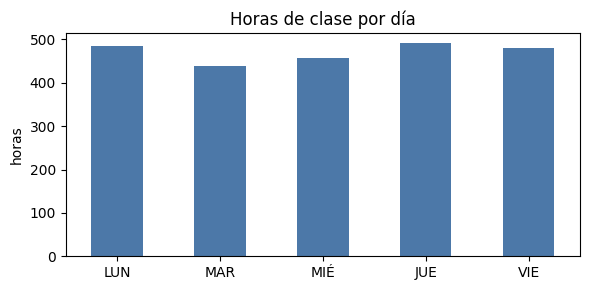

In [14]:
def resumen_solucion(df):
    ocupacion = [datos["clases"][c]["cantidad_alumnos"] / datos["aulas"][a]["capacidad"]
                 for c, a in zip(df["Clase"], df["Aula"])]
    filas = {
        "Clases asignadas": len(df),
        "Cohortes": df["Cohorte"].nunique(),
        "Profesores": df["Profesor"].nunique(),
        "Aulas usadas": f"{df['Aula'].nunique()} de {len(datos['aulas'])}",
        "Ocupación media de los asientos": f"{100 * sum(ocupacion) / len(ocupacion):.0f} %",
        "Horas de clase por semana": round(df["Duración (min)"].sum() / 60),
    }
    for nombre, valor in filas.items():
        print(f"{nombre:<34}{valor}")

    horas_por_dia = (df.groupby("Día")["Duración (min)"].sum() / 60).reindex(dias_unicos)
    ax = horas_por_dia.plot(kind="bar", figsize=(6, 3), color="#4C78A8", rot=0)
    ax.set_title("Horas de clase por día")
    ax.set_xlabel("")
    ax.set_ylabel("horas")
    plt.tight_layout()
    plt.show()

resumen_solucion(df_solucion)

## 2. Grilla semanal

La función `dibujar_grilla` dibuja la semana de una cohorte, un profesor o un aula. Cada bloque muestra la materia y, abajo, los otros dos datos (por ejemplo, en la vista de una cohorte: el aula y el profesor).

In [15]:
def dibujar_grilla(df, columna, valor):
    """columna: 'Cohorte', 'Profesor' o 'Aula'. Dibuja la semana de ese valor."""
    sub = df[df[columna] == valor]
    otros = [c for c in ("Cohorte", "Profesor", "Aula") if c != columna]

    # Los límites horarios salen de toda la solución, así todas las grillas son comparables
    t0 = min(time_to_mins(i) for i in df["Inicio"]) // 60 * 60
    t1 = -(-max(time_to_mins(f) for f in df["Fin"]) // 60) * 60

    fig, ax = plt.subplots(figsize=(11, 6))
    colores = plt.cm.tab20.colors
    for k, fila in enumerate(sub.to_dict("records")):
        x = dias_unicos.index(fila["Día"])
        ini, fin = time_to_mins(fila["Inicio"]), time_to_mins(fila["Fin"])
        ax.add_patch(plt.Rectangle((x + 0.04, ini), 0.92, fin - ini,
                                   facecolor=colores[k % len(colores)], alpha=0.85, edgecolor="white"))
        materia = textwrap.shorten(textwrap.fill(fila["Materia"], 22), width=44, placeholder="…")
        ax.text(x + 0.5, (ini + fin) / 2, f"{materia}\n{fila[otros[0]]} · {fila[otros[1]]}",
                ha="center", va="center", fontsize=7.5)

    ax.set_xlim(0, len(dias_unicos))
    ax.set_ylim(t1, t0)                                   # el horario temprano arriba
    ax.set_xticks([i + 0.5 for i in range(len(dias_unicos))])
    ax.set_xticklabels(dias_unicos)
    ax.xaxis.tick_top()
    ax.set_yticks(range(t0, t1 + 1, 60))
    ax.set_yticklabels([f"{m // 60:02d}:00" for m in range(t0, t1 + 1, 60)])
    ax.grid(axis="y", color="#DDDDDD", linewidth=0.8)
    ax.set_title(f"{columna}: {valor}  ({len(sub)} clases, {sub['Duración (min)'].sum() / 60:.0f} h)", pad=28)
    plt.tight_layout()
    plt.show()
    return sub

## 3. Interfaz

In [16]:
def interfaz_grilla(df):
    columnas_tabla = ["Materia", "Día", "Inicio", "Fin", "Cohorte", "Profesor", "Aula"]
    orden_dias = {d: i for i, d in enumerate(dias_unicos)}

    def opciones(columna):
        return sorted(df[columna].unique())

    def mostrar(columna, valor):
        sub = dibujar_grilla(df, columna, valor)
        tabla = sub.sort_values(["Día", "Inicio"], key=lambda s: s.map(orden_dias) if s.name == "Día" else s)
        display(tabla[columnas_tabla].reset_index(drop=True))

    if widgets is None:                       # sin ipywidgets: muestra la primera cohorte
        mostrar("Cohorte", opciones("Cohorte")[0])
        return

    ver_por = widgets.Dropdown(options=["Cohorte", "Profesor", "Aula"], description="Ver por:")
    elegir = widgets.Dropdown(options=opciones("Cohorte"), description="Elegir:")
    salida = widgets.Output()

    def refrescar(*_):
        with salida:
            clear_output(wait=True)
            mostrar(ver_por.value, elegir.value)

    def cambiar_tipo(*_):
        elegir.options = opciones(ver_por.value)
        refrescar()

    ver_por.observe(cambiar_tipo, "value")
    elegir.observe(refrescar, "value")
    display(widgets.HBox([ver_por, elegir]), salida)
    refrescar()

interfaz_grilla(df_solucion)

Output()

# Parte 4: Si bajamos las aulas o los profesores?

In [17]:
# =============================================================================
#  PRUEBAS DE ESTRÉS: herramientas compartidas
#  Estas pruebas responden "¿hasta cuándo existe un horario válido?", así que arman
#  solo las restricciones duras D1–D7 (sin función objetivo) y preguntan si hay solución.
# =============================================================================
import time
import matplotlib.pyplot as plt

TIEMPO_ESCENARIO_S = 600     # límite del solver en cada escenario
SEMILLA = 42                # para que el sorteo de qué se quita sea reproducible
PARAR_AL_ROMPER = True      # True: corta en el primer escenario infactible (ahorra tiempo)


def resolver_factibilidad(d, tiempo_s=TIEMPO_ESCENARIO_S, candidatos=None):
    """d: diccionario como el que devuelve preparar_datos. Devuelve (estado, segundos).
    candidatos: {clase_id: [docentes posibles]}. Si una clase está en el diccionario, el solver
    elige cuál de esos docentes la dicta; si no, la dicta su docente de siempre."""
    t0 = time.time()
    m = cp_model.CpModel()
    ocup_aula, ocup_prof, ocup_coh, min_dia = {}, {}, {}, {}
    candidatos = candidatos or {}

    for c_id, c in d["clases"].items():
        dur = int(c["duracion_min"])
        dur_slots = dur // SLOT_DURATION
        coh = c["cohorte"]
        docentes = candidatos.get(c_id, [c["profesor_id"]])
        opciones = []
        for dia in d["dias"]:
            if (dia, c["franja"]) not in d["ventanas"]:
                continue
            a, b = d["ventanas"][dia, c["franja"]]
            for ini in range(a, b - dur + 1, SLOT_DURATION):          # D1
                s = slot_de(ini)
                zs = []                                                # un z por docente posible
                for prof in docentes:
                    libres = d["minutos_disponibles"].get((prof, dia), set())
                    if not all(t in libres for t in range(ini, ini + dur, SLOT_DURATION)):   # D5
                        continue
                    z = m.NewBoolVar("")
                    zs.append(z)
                    for k in range(s, s + dur_slots):
                        ocup_prof.setdefault((prof, dia, k), []).append(z)
                    min_dia.setdefault((prof, dia), []).append((dur, z))
                if not zs:
                    continue
                if len(zs) == 1:
                    yv = zs[0]
                else:
                    yv = m.NewBoolVar("")
                    m.Add(sum(zs) == yv)                               # un solo docente la dicta
                opciones.append(yv)
                xs = []
                for aula in d["aulas_compatibles"][c_id]:              # D2, D3
                    v = m.NewBoolVar("")
                    xs.append(v)
                    for k in range(s, s + dur_slots):
                        ocup_aula.setdefault((aula, dia, k), []).append(v)
                m.Add(sum(xs) == yv)
                for k in range(s, s + dur_slots):
                    ocup_coh.setdefault((coh, dia, k), []).append(yv)
        if not opciones:
            return "Infactible", time.time() - t0
        m.AddExactlyOne(opciones)                                      # D1

    for grupo in (ocup_aula, ocup_prof, ocup_coh):                     # D4, D5, D6
        for variables in grupo.values():
            if len(variables) > 1:
                m.AddAtMostOne(variables)
    for (prof, dia), lista in min_dia.items():                         # D7
        m.Add(sum(du * v for du, v in lista) <= int(d["docentes"][prof]["max_min_por_dia"]))

    solver = cp_model.CpSolver()
    solver.parameters.max_time_in_seconds = tiempo_s
    solver.parameters.num_workers = 8
    estado = solver.Solve(m)
    nombre = {cp_model.OPTIMAL: "Factible", cp_model.FEASIBLE: "Factible",
              cp_model.INFEASIBLE: "Infactible"}.get(estado, "Sin resolver (tiempo)")
    return nombre, time.time() - t0

def graficar_escenarios(df, col_x, col_y, titulo, etiqueta_x, etiqueta_y):
    colores = {"Factible": "#2E8B57", "Infactible": "#C0392B", "Sin resolver (tiempo)": "#E69F00"}
    fig, ax = plt.subplots(figsize=(7, 3.5))
    ax.plot(df[col_x], df[col_y], color="#999999", zorder=1)
    for estado, g in df.groupby("estado"):
        ax.scatter(g[col_x], g[col_y], color=colores.get(estado, "gray"), label=estado, s=60, zorder=2)
    ax.axhline(100, ls="--", color="#999999", lw=1)
    ax.invert_xaxis()                                   # de más recursos a menos
    ax.set_title(titulo)
    ax.set_xlabel(etiqueta_x)
    ax.set_ylabel(etiqueta_y)
    ax.legend()
    plt.tight_layout()
    plt.show()

print("Herramientas de pruebas de estrés listas.")

Herramientas de pruebas de estrés listas.


## 1. Menos aulas

In [ ]:
# =============================================================================
#  PRUEBA 1: ¿Cuántas aulas se pueden sacar antes de que el modelo no tenga solución?
#  Se sortean las aulas en un orden fijo y en cada escenario se conserva una fracción
#  (los escenarios están anidados: el de 60% conserva las mismas aulas que el de 80% menos algunas).
# =============================================================================
FRACCIONES_AULAS = [1.0, 0.8, 0.7, 0.65, 0.6, 0.5, 0.4, 0.3]     # fracción de aulas que se conserva

aulas_al_azar = dfs["aulas.csv"].sample(frac=1, random_state=SEMILLA).aula_id.tolist()


def ocupacion_por_franja(d, n_aulas):
    """Minutos de clase pedidos / minutos de aula disponibles, por franja (en %)."""
    pedidos, disponibles = {}, {}
    for c in d["clases"].values():
        pedidos[c["franja"]] = pedidos.get(c["franja"], 0) + int(c["duracion_min"])
    for (dia, franja), (a, b) in d["ventanas"].items():
        disponibles[franja] = disponibles.get(franja, 0) + (b - a) * n_aulas
    return {f: 100 * pedidos[f] / disponibles[f] for f in pedidos if disponibles.get(f)}


filas = []
for fraccion in FRACCIONES_AULAS:
    n = max(1, round(fraccion * len(aulas_al_azar)))
    quedan = set(aulas_al_azar[:n])
    au = dfs["aulas.csv"]
    d_esc = preparar_datos({**dfs, "aulas.csv": au[au.aula_id.isin(quedan)]})

    sin_aula = [c for c, aulas in d_esc["aulas_compatibles"].items() if not aulas]
    ocupacion = ocupacion_por_franja(d_esc, n)
    franja_max = max(ocupacion, key=ocupacion.get)

    # Condiciones necesarias: si no se cumplen, el modelo es infactible sin necesidad de resolverlo
    if sin_aula:
        estado, motivo, seg = "Infactible", "hay clases sin aula compatible", 0
    elif ocupacion[franja_max] > 100:
        estado, motivo, seg = "Infactible", "faltan horas de aula en una franja", 0
    else:
        estado, seg = resolver_factibilidad(d_esc)
        motivo = "resuelto por el solver"

    filas.append({
        "% de aulas": round(100 * fraccion),
        "aulas": n,
        "laboratorios": int(au[au.aula_id.isin(quedan)].es_laboratorio.sum()),
        "clases sin aula compatible": len(sin_aula),
        "franja más cargada": franja_max,
        "ocupación de esa franja (%)": round(ocupacion[franja_max], 1),
        "estado": estado,
        "motivo": motivo,
        "segundos": round(seg, 1),
    })
    print(f"{round(100 * fraccion):>4}% de las aulas ({n}): {estado}")
    if PARAR_AL_ROMPER and estado != "Factible":
        break

df_estres_aulas = pd.DataFrame(filas)
display(df_estres_aulas)
graficar_escenarios(df_estres_aulas, "aulas", "ocupación de esa franja (%)",
                    "Menos aulas: ocupación de la franja más cargada",
                    "cantidad de aulas", "ocupación (%)")

ok = df_estres_aulas[df_estres_aulas.estado == "Factible"]
rompe = df_estres_aulas[df_estres_aulas.estado == "Infactible"]
sin_res = df_estres_aulas[df_estres_aulas.estado == "Sin resolver (tiempo)"]
if not ok.empty:
    print(f"Último escenario con solución: {int(ok.aulas.iloc[-1])} aulas ({int(ok['% de aulas'].iloc[-1])}%).")
if not sin_res.empty:
    print(f"Sin resolver en {TIEMPO_ESCENARIO_S} s: {', '.join(str(int(a)) for a in sin_res.aulas)} aulas "
          "(no se sabe si hay solución: subir TIEMPO_ESCENARIO_S).")
if not rompe.empty:
    print(f"Primer escenario que rompe (probado infactible): {int(rompe.aulas.iloc[0])} aulas "
          f"({int(rompe['% de aulas'].iloc[0])}%), motivo: {rompe.motivo.iloc[0]}.")
else:
    print("Todavía ningún escenario se probó infactible.")

 100% de las aulas (200): Factible
  80% de las aulas (160): Factible


## 2. Menos profesores

In [ ]:
# =============================================================================
#  PRUEBA 2: ¿Cuántos profesores se pueden sacar antes de que el modelo no tenga solución?
#  Si se va un profesor, sus clases quedan "huérfanas" y las tiene que dictar otro. En vez de
#  repartirlas a mano, el solver ELIGE quién dicta cada una entre sus docentes candidatos:
#    - los profesores que ya dictan esa misma materia (hasta MAX_CANDIDATOS, los menos cargados);
#    - si hay menos de MIN_CANDIDATOS, se completa con otros docentes que puedan dictarla.
#  Los candidatos tienen que tener un hueco para esa clase en su franja y respetar max_min_por_dia.
#  Capacidad semanal de un docente = Σ por día de min(max_min_por_dia, minutos disponibles ese día).
# =============================================================================
FRACCIONES_PROFES = [1.0, 0.95, 0.9, 0.8, 0.7, 0.6, 0.5]   # fracción de profesores que se conserva
MAX_CANDIDATOS = 10      # docentes candidatos por clase huérfana (más = modelo más grande)
MIN_CANDIDATOS = 3       # mínimo de candidatos por clase huérfana

profes_al_azar = dfs["profesores.csv"].sample(frac=1, random_state=SEMILLA).profesor_id.tolist()


def puede_dictar(prof, franja, dur, libres):
    """¿Tiene el docente algún hueco de `dur` minutos dentro de la franja, algún día?"""
    for dia in dias_unicos:
        if (dia, franja) not in ventana:
            continue
        a, b = ventana[dia, franja]
        disp = libres.get((prof, dia), ())
        for ini in range(a, b - dur + 1, SLOT_DURATION):
            if all(t in disp for t in range(ini, ini + dur, SLOT_DURATION)):
                return True
    return False


def escenario_profesores(dfs, fraccion):
    n = max(1, round(fraccion * len(profes_al_azar)))
    quedan = profes_al_azar[:n]
    quedan_set = set(quedan)
    cl = dfs["clases.csv"]
    pr = dfs["profesores.csv"][dfs["profesores.csv"].profesor_id.isin(quedan_set)].copy()
    dp = dfs["disponibilidad_profesores.csv"]
    dp = dp[dp.profesor_id.isin(quedan_set)].copy()

    libres = minutos_disponibles_de(dp)
    max_dia = pr.set_index("profesor_id").max_min_por_dia.astype(int).to_dict()
    capacidad = {p: sum(min(max_dia[p], len(libres.get((p, dia), ())) * SLOT_DURATION) for dia in dias_unicos)
                 for p in quedan}
    carga = {p: 0 for p in quedan}              # carga actual (solo sus clases propias), para ordenar candidatos
    materias = {p: set() for p in quedan}
    for r in cl[cl.profesor_id.isin(quedan_set)].itertuples():
        carga[r.profesor_id] += int(r.duracion_min)
        materias[r.profesor_id].add(r.materia)

    cache = {}
    def ok(p, franja, dur):
        if (p, franja, dur) not in cache:
            cache[p, franja, dur] = puede_dictar(p, franja, dur, libres)
        return cache[p, franja, dur]

    candidatos, sin_misma_materia, sin_candidatos = {}, 0, 0
    for r in cl[~cl.profesor_id.isin(quedan_set)].itertuples():
        dur = int(r.duracion_min)
        def aptos(grupo):
            return sorted((p for p in grupo if dur <= max_dia[p] and ok(p, r.franja, dur)),
                          key=lambda p: carga[p] / max(capacidad[p], 1))
        mismos = aptos([p for p in quedan if r.materia in materias[p]])
        lista = mismos[:MAX_CANDIDATOS]
        if not mismos:
            sin_misma_materia += 1
        if len(lista) < MIN_CANDIDATOS:
            lista += [p for p in aptos(quedan) if p not in lista][:MIN_CANDIDATOS - len(lista)]
        if not lista:
            sin_candidatos += 1
        candidatos[r.clase_id] = lista

    metricas = {
        "n": n,
        "huerfanas": len(candidatos),
        "cand_prom": sum(len(v) for v in candidatos.values()) / max(len(candidatos), 1),
        "sin_misma_materia": sin_misma_materia,
        "sin_candidatos": sin_candidatos,
        "carga_total": 100 * int(cl.duracion_min.sum()) / max(sum(capacidad.values()), 1),
    }
    return {**dfs, "profesores.csv": pr, "disponibilidad_profesores.csv": dp}, candidatos, metricas


filas = []
for fraccion in FRACCIONES_PROFES:
    dfs_esc, candidatos, mt = escenario_profesores(dfs, fraccion)
    d_esc = preparar_datos(dfs_esc)

    # Condiciones necesarias: si no se cumplen, es infactible sin necesidad de resolverlo
    if mt["sin_candidatos"]:
        estado, motivo, seg = "Infactible", "hay clases que ningún docente puede dictar", 0
    elif mt["carga_total"] > 100:
        estado, motivo, seg = "Infactible", "la carga total supera la capacidad docente", 0
    else:
        estado, seg = resolver_factibilidad(d_esc, candidatos=candidatos)
        motivo = "el solver no terminó a tiempo" if estado.startswith("Sin") else "resuelto por el solver"

    filas.append({
        "% de profesores": round(100 * fraccion),
        "profesores": mt["n"],
        "clases a reasignar": mt["huerfanas"],
        "candidatos por clase (prom.)": round(mt["cand_prom"], 1),
        "clases sin otro docente de su materia": mt["sin_misma_materia"],
        "carga total (% de capacidad)": round(mt["carga_total"], 1),
        "estado": estado,
        "motivo": motivo,
        "segundos": round(seg, 1),
    })
    print(f"{round(100 * fraccion):>4}% de los profesores ({mt['n']}): {estado}")
    if PARAR_AL_ROMPER and estado == "Infactible":
        break

df_estres_profes = pd.DataFrame(filas)
display(df_estres_profes)
graficar_escenarios(df_estres_profes, "profesores", "carga total (% de capacidad)",
                    "Menos profesores: carga total sobre la capacidad docente",
                    "cantidad de profesores", "carga total (% de capacidad)")

ok_ = df_estres_profes[df_estres_profes.estado == "Factible"]
rompe = df_estres_profes[df_estres_profes.estado == "Infactible"]
sin_res = df_estres_profes[df_estres_profes.estado == "Sin resolver (tiempo)"]
if not ok_.empty:
    print(f"Último escenario con solución: {int(ok_.profesores.iloc[-1])} profesores ({int(ok_['% de profesores'].iloc[-1])}%).")
if not sin_res.empty:
    print(f"Sin resolver en {TIEMPO_ESCENARIO_S} s: {', '.join(str(int(p)) for p in sin_res.profesores)} profesores "
          "(no se sabe si hay solución: subir TIEMPO_ESCENARIO_S).")
if not rompe.empty:
    print(f"Primer escenario que rompe (probado infactible): {int(rompe.profesores.iloc[0])} profesores "
          f"({int(rompe['% de profesores'].iloc[0])}%), motivo: {rompe.motivo.iloc[0]}.")
else:
    print("Todavía ningún escenario se probó infactible.")